In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from collections import Counter
import re
import warnings
warnings.filterwarnings('ignore')

db_path = "../data/raw/news.db"
sns.set_theme(style='whitegrid', palette='muted')

In [4]:
conn = sqlite3.connect(db_path)
df = pd.read_sql('SELECT * FROM articles', conn, parse_dates=['published_at', 'fetched_at'])
conn.close()

print(f"Total {len(df)} articles added")
print(f"Date range: {df.published_at.min().date()} to {df.published_at.max().date()}")

df.head(5)

Total 616 articles added
Date range: 2026-05-21 to 2026-05-27


,id,title,text,source,author,url,published_at,fetched_at
0,02d453ab93ed,This Biotech Stock Is Up 355%. One Fund Added ...,"If you click 'Accept all', we and our partners...",Yahoo Entertainment,unknown,https://consent.yahoo.com/v2/collectConsent?se...,2026-05-24 14:33:59+00:00,2026-05-25 14:34:53.370995+00:00
1,641248f25a0e,Hello! AirPods Pro 3 drop to one of the best p...,It’s back folks! Amazon is once again offering...,9to5Toys,Justin Kahn,http://9to5toys.com/2026/05/24/airpods-pro-3-b...,2026-05-24 14:29:00+00:00,2026-05-25 14:34:53.370995+00:00
2,2a809966af4a,Amazon Outlet Memorial Day Sale: Up to 70% off...,"As part of Amazon's Memorial Day Sale, get dea...",Dealnews.com,unknown,https://www.dealnews.com/Amazon-Outlet-Memoria...,2026-05-24 14:28:08+00:00,2026-05-25 14:34:53.370995+00:00
3,44ffb94a56af,Silver Mines are the New ETF Income Play With ...,Mining has long been a notoriously cost intens...,24/7 Wall St.,John Seetoo,https://247wallst.com/investing/2026/05/24/sil...,2026-05-24 14:26:33+00:00,2026-05-25 14:34:53.370995+00:00
4,5187f27d4cef,This SaaS Stock Raised Its 2026 Outlook. A Fun...,"If you click 'Accept all', we and our partners...",Yahoo Entertainment,unknown,https://consent.yahoo.com/v2/collectConsent?se...,2026-05-24 14:26:30+00:00,2026-05-25 14:34:53.370995+00:00


In [ ]:
print('Shape:', df.shape)
print('\nColumn types:')
print(df.dtypes)

Shape: (616, 8)

Column types:
id                              str
title                           str
text                            str
source                          str
author                          str
url                             str
published_at    datetime64[us, UTC]
fetched_at      datetime64[us, UTC]
dtype: object

Memory usage: 501.6962890625 KB


In [9]:
missing = df.isnull().sum()
missing_df = pd.DataFrame({'missing_count': missing})
missing_df = missing_df[missing_df.missing_count > 0]

if missing_df.empty:
    print('No missing values found!')
else:
    print(missing_df)
    # Visualise
    missing_df['missing_count'].plot(kind='barh', color='salmon')
    plt.title('Missing Values by Column')
    plt.xlabel('number that are missing')
    plt.tight_layout()
    plt.show()

No missing values found!


In [ ]:
id_dupes = df.duplicated(subset='id').sum()
title_dupes = df.duplicated(subset='title').sum()
print(f'Duplicate IDs:    {id_dupes}')
print(f'Duplicate titles: {title_dupes}')

# Drop title dupes (same story, different source)
df_clean = df.drop_duplicates(subset='title').copy()
print(f'\nRows after dedup: {df_clean.shape[0]} (removed {df.shape[0] - df_clean.shape[0]})')

Duplicate IDs:    0
Duplicate titles: 7

Rows after dedup: 609 (removed 7)


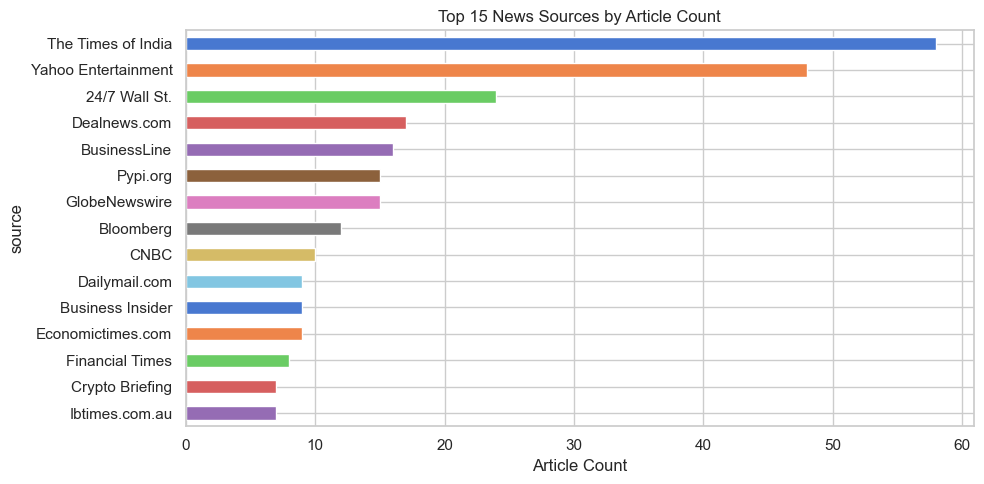


Total unique sources: 209


In [24]:
top_sources = df_clean['source'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 5))
top_sources.plot(kind='barh', ax=ax, color=sns.color_palette('muted', 15))
ax.invert_yaxis()
ax.set_title('Top 15 News Sources by Article Count')
ax.set_xlabel('Article Count')
plt.tight_layout()
plt.show()

print(f'\nTotal unique sources: {df_clean.source.nunique()}')

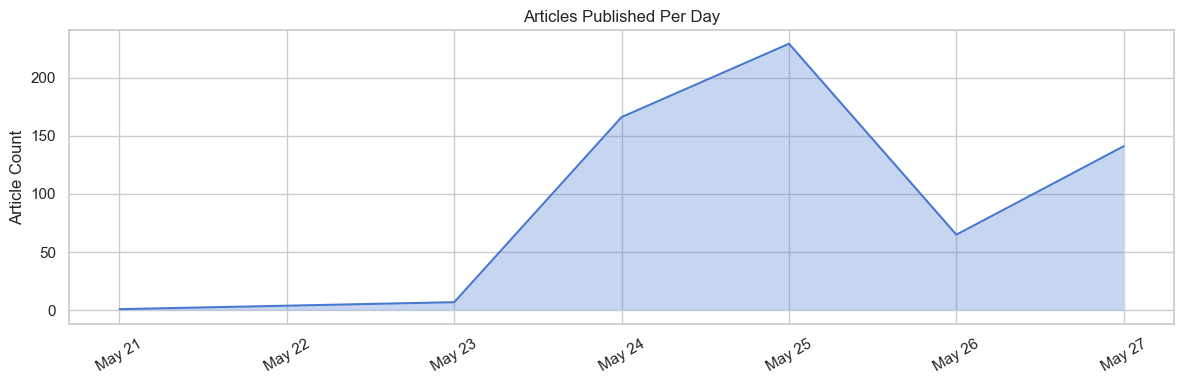

Avg articles/day: 101.5
Max articles/day: 229 on 2026-05-25


In [29]:
df_clean['date'] = df_clean['published_at'].dt.date
daily_counts = df_clean.groupby('date').size().reset_index(name='count')
daily_counts['date'] = pd.to_datetime(daily_counts['date'])

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(daily_counts['date'], daily_counts['count'], alpha=0.3)
ax.plot(daily_counts['date'], daily_counts['count'], linewidth=1.5)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_title('Articles Published Per Day')
ax.set_ylabel('Article Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print(f'Avg articles/day: {daily_counts["count"].mean():.1f}')
print(f'Max articles/day: {daily_counts["count"].max()} on {daily_counts.loc[daily_counts["count"].idxmax(), "date"].date()}')

In [ ]:
df_clean.head(5)

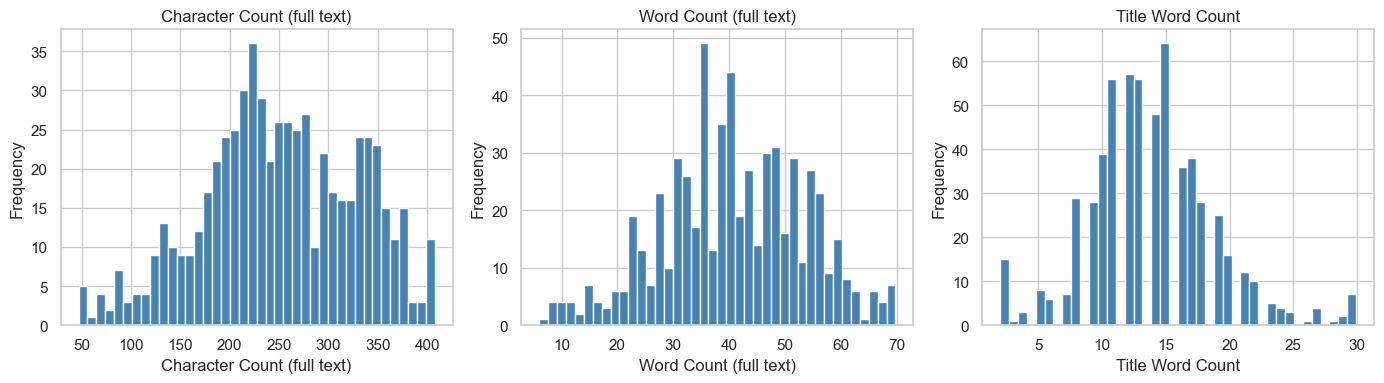

       char_count  word_count  title_words
count       609.0       609.0        609.0
mean        251.6        40.8         13.9
std          80.3        13.2          5.5
min          47.0         6.0          2.0
25%         200.0        32.0         11.0
50%         248.0        41.0         13.0
75%         314.0        50.0         17.0
max         633.0       106.0         63.0

⚠️  0.0% of articles exceed 512 tokens — truncation will apply in RoBERTa.


In [30]:
# Combine title + text as the full input we'll feed to models
df_clean['full_text'] = (df_clean['title'].fillna('') + ' ' + df_clean['text'].fillna('')).str.strip()
df_clean['char_count']  = df_clean['full_text'].str.len()
df_clean['word_count']  = df_clean['full_text'].str.split().str.len()
df_clean['title_words'] = df_clean['title'].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, col, label in zip(axes,
    ['char_count', 'word_count', 'title_words'],
    ['Character Count (full text)', 'Word Count (full text)', 'Title Word Count']):
    df_clean[col].clip(upper=df_clean[col].quantile(0.99)).hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

print(df_clean[['char_count','word_count','title_words']].describe().round(1))

# Key insight for modeling
over_512 = (df_clean['word_count'] > 512).mean()
print(f'\n⚠️  {over_512:.1%} of articles exceed 512 tokens — truncation will apply in RoBERTa.')

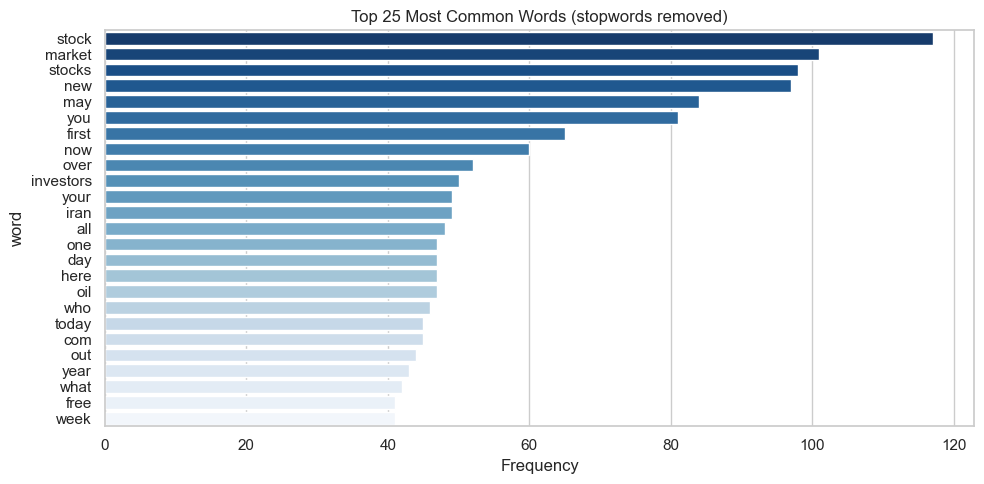

In [31]:
STOPWORDS = set([
    'the','a','an','and','or','but','in','on','at','to','for','of',
    'is','it','its','was','are','be','been','this','that','with',
    'as','by','from','have','has','had','he','she','they','we',
    'will','not','can','said','says','after','about','more','also',
    'than','were','would','could','their','his','her','our','which'
])

all_words = ' '.join(df_clean['full_text'].dropna()).lower()
words = re.findall(r'[a-z]{3,}', all_words)
filtered = [w for w in words if w not in STOPWORDS]
top_words = Counter(filtered).most_common(25)

words_df = pd.DataFrame(top_words, columns=['word', 'count'])
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=words_df, x='count', y='word', palette='Blues_r', ax=ax)
ax.set_title('Top 25 Most Common Words (stopwords removed)')
ax.set_xlabel('Frequency')
plt.tight_layout()
plt.show()

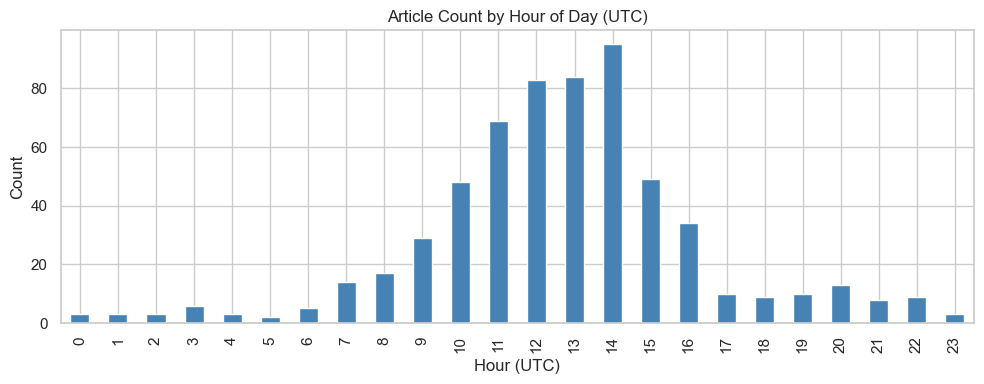

In [32]:
df_clean['hour'] = df_clean['published_at'].dt.hour

fig, ax = plt.subplots(figsize=(10, 4))
df_clean['hour'].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Article Count by Hour of Day (UTC)')
ax.set_xlabel('Hour (UTC)')
ax.set_ylabel('Count')
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()

In [33]:
# Flag low-quality rows
df_clean['is_low_quality'] = (
    (df_clean['word_count'] < 5) |          # too short to be useful
    (df_clean['text'].isna()) |             # no body text
    (df_clean['full_text'].str.contains(r'\[\+\d+ chars\]', regex=True))  # NewsAPI truncation marker
)

lq = df_clean['is_low_quality'].sum()
print(f'Low quality rows flagged: {lq} ({lq/len(df_clean):.1%})')

# Clean version ready for modeling
df_model = df_clean[~df_clean['is_low_quality']].copy()

# Strip NewsAPI truncation marker from text
df_model['text'] = df_model['text'].str.replace(r'\[\+\d+ chars\]', '', regex=True).str.strip()

print(f'\nFinal clean dataset: {len(df_model):,} articles ready for modeling')
print(f'Columns available: {list(df_model.columns)}')

# Save for use in Week 2
df_model.to_csv('../data/processed/articles_clean.csv', index=False)
print('\n✅ Saved to data/processed/articles_clean.csv')

Low quality rows flagged: 24 (3.9%)

Final clean dataset: 585 articles ready for modeling
Columns available: ['id', 'title', 'text', 'source', 'author', 'url', 'published_at', 'fetched_at', 'date', 'full_text', 'char_count', 'word_count', 'title_words', 'hour', 'is_low_quality']

✅ Saved to data/processed/articles_clean.csv
